# Utilities

## Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import re, string, Levenshtein, joblib
import numpy as np

from collections import Counter

# Natural language processing
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

# Data science
from sklearn.feature_extraction.text import TfidfVectorizer

# Visualization
from wordcloud import WordCloud

## Functions

In [2]:
# For index_terms treatment, list_flatten and dict_flatten are defined.

def list_flatten(my_list):

    result = []

    # Iterate over my_list
    for element in my_list:

        # If it is a list, unpack and append to result
        if isinstance(element, list):
            result.extend(list_flatten(element))

        # If it is a string
        elif isinstance(element, str):
            element = element.strip() # Remove start/end spaces
            result.append(element)    # Append to result
        
        # Else raise error
        else:
            raise TypeError('Element is not list or string.')

    return result

def dict_flatten(my_dict):
    
    result = []

    # Iterate over my_dict
    for key, val in my_dict.items():

        # If it is a dictionary, unpack and append to result
        if isinstance(val, dict):
            result.extend(dict_flatten(val))
        
        # If it is a list, unpack and append to result
        elif isinstance(val, list):
            result.extend(val)        
        
        # Else raise error
        else:
            raise TypeError('Element is not dictionary or list')
    
    return result

# Text preprocessing
def preprocess_text(text, words2remove):
    text = text.lower()                                                  # Lower case
    text = re.sub(r'[^a-z\s]', ' ', text)                                # Remove numbers and special characteres
    # split(r'\s+') is the same as word_tokenize()
    # if the text doesn´t have special characters
    # text = text.split(r'\s+')                                          # Remove multiple spaces, convert to list
    tokens = word_tokenize(text)                                         # Tokenization
    tokens = [word for word in tokens if word not in stop_words]         # Remove stopwords
    tokens = [word for word in tokens if word not in string.punctuation] # Remove punctuation
    tokens = [word for word in tokens if word not in words2remove]       # Remove words from custom list
    tokens = [lemmatizer.lemmatize(word) for word in tokens]             # Lemmatization
    return ' '.join(tokens)

# Word clouds for given string
def word_cloud(text, save_figure):
    w = 10
    h = 5
    word_freq = Counter(text.split(' '))
    wordcloud = WordCloud(width=w * 100, height=h * 100,
                           background_color='white',
                           stopwords=None,
                           min_font_size=10).generate_from_frequencies(word_freq)
    plt.figure(figsize=(w, h), facecolor=None)
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.tight_layout(pad=0)
    if save_figure:
        plt.savefig(f'../data/output/{save_figure}.pdf')
    plt.show()

# Data formatting

In [3]:
# Load data
data = pd.read_csv('../data/input/api/data.csv')
display(data.shape)
display(data.head())

(11373, 7)

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count,html_url
0,0,$\beta$-Ga2O3 in Power Electronics Converters:...,"{'ieee_terms': {'terms': ['Schottky diodes', '...",20240410,"In this work, the possibility of using differe...",7,https://ieeexplore.ieee.org/document/10496151/
1,0,(2N+1) Selective Harmonic Elimination-PWM for ...,"{'ieee_terms': {'terms': ['Switches', 'Harmoni...",20170209,The performance of modular multilevel converte...,76,https://ieeexplore.ieee.org/document/7849220/
2,0,1-D Convolutional Neural Networks for Signal P...,{'ieee_terms': {'terms': ['Electrocardiography...,20190417,1D Convolutional Neural Networks (CNNs) have r...,222,https://ieeexplore.ieee.org/document/8682194/
3,0,1-MW Full-Bridge MMC for High-Current Low-Volt...,{'dynamic_index_terms': {'terms': ['Low Voltag...,20200826,A full-bridge modular multilevel converter (MM...,0,https://ieeexplore.ieee.org/document/9178138/
4,0,1-kV Input 1-MHz GaN Modular Multilevel LLC Co...,"{'ieee_terms': {'terms': ['Silicon carbide', '...",20190527,A modular multilevel LLC converter suitable fo...,3,https://ieeexplore.ieee.org/document/8721944/


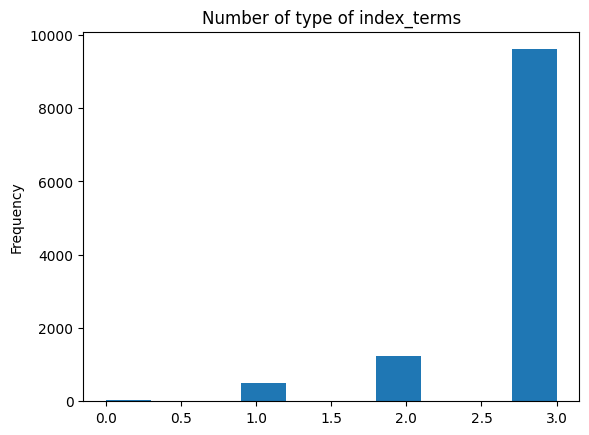

In [4]:
# Count number of type of index_terms
list_terms = [len(eval(dic_index_term).keys()) for dic_index_term in data['index_terms'].values]

plt.figure()
plt.hist(list_terms)
plt.title('Number of type of index_terms')
plt.ylabel('Frequency')
plt.show()

In [5]:
# Sample index_terms value
sample = data.iloc[0]['index_terms']

In [6]:
# The solution is to append all terms to a flat list
dic_terms = eval(sample)
dic_terms

{'ieee_terms': {'terms': ['Schottky diodes',
   'Costs',
   'Performance evaluation',
   'Diamonds',
   'Silicon carbide',
   'Power electronics',
   'Thermal conductivity']},
 'author_terms': {'terms': ['  $\\beta$  -Ga  $_2$  0  $_3$  ',
   'diamond',
   'gallium oxide',
   'HVDC converters',
   'ultra-wide-bandgap']},
 'dynamic_index_terms': {'terms': ['Power Electronics',
   'Power Electronic Converters',
   'High Power',
   'Temperature Rise',
   'Incumbent',
   'Re-election',
   'Device Applications',
   'Power Loss',
   'Thermal Resistance',
   'Power Conversion',
   'Computer-aided Design',
   'Power Devices',
   'Power Transistors',
   'Power Semiconductor Devices',
   'Semiconductor Devices',
   'Converter Operation',
   'Performance Of Converter',
   'Power Semiconductor',
   'Modular Multilevel Converter',
   'On-state Resistance',
   'Blocking Voltage',
   'High Voltage',
   'Higher Tendency',
   'Thermal Conductivity',
   'Heat Conduction',
   'Power System',
   'Si Devic

In [7]:
# Flatten dictionary
dict_flatten(dic_terms)

['Schottky diodes',
 'Costs',
 'Performance evaluation',
 'Diamonds',
 'Silicon carbide',
 'Power electronics',
 'Thermal conductivity',
 '  $\\beta$  -Ga  $_2$  0  $_3$  ',
 'diamond',
 'gallium oxide',
 'HVDC converters',
 'ultra-wide-bandgap',
 'Power Electronics',
 'Power Electronic Converters',
 'High Power',
 'Temperature Rise',
 'Incumbent',
 'Re-election',
 'Device Applications',
 'Power Loss',
 'Thermal Resistance',
 'Power Conversion',
 'Computer-aided Design',
 'Power Devices',
 'Power Transistors',
 'Power Semiconductor Devices',
 'Semiconductor Devices',
 'Converter Operation',
 'Performance Of Converter',
 'Power Semiconductor',
 'Modular Multilevel Converter',
 'On-state Resistance',
 'Blocking Voltage',
 'High Voltage',
 'Higher Tendency',
 'Thermal Conductivity',
 'Heat Conduction',
 'Power System',
 'Si Devices',
 'Power Sector',
 'Rated Power',
 'Converter Topology',
 'Switching Loss',
 'Schottky Diode',
 'Schottky Barrier Diodes',
 'Submodule',
 'Thermal Management'

In [8]:
# Flatten list
list_flatten(dict_flatten(dic_terms))

['Schottky diodes',
 'Costs',
 'Performance evaluation',
 'Diamonds',
 'Silicon carbide',
 'Power electronics',
 'Thermal conductivity',
 '$\\beta$  -Ga  $_2$  0  $_3$',
 'diamond',
 'gallium oxide',
 'HVDC converters',
 'ultra-wide-bandgap',
 'Power Electronics',
 'Power Electronic Converters',
 'High Power',
 'Temperature Rise',
 'Incumbent',
 'Re-election',
 'Device Applications',
 'Power Loss',
 'Thermal Resistance',
 'Power Conversion',
 'Computer-aided Design',
 'Power Devices',
 'Power Transistors',
 'Power Semiconductor Devices',
 'Semiconductor Devices',
 'Converter Operation',
 'Performance Of Converter',
 'Power Semiconductor',
 'Modular Multilevel Converter',
 'On-state Resistance',
 'Blocking Voltage',
 'High Voltage',
 'Higher Tendency',
 'Thermal Conductivity',
 'Heat Conduction',
 'Power System',
 'Si Devices',
 'Power Sector',
 'Rated Power',
 'Converter Topology',
 'Switching Loss',
 'Schottky Diode',
 'Schottky Barrier Diodes',
 'Submodule',
 'Thermal Management',
 '

In [9]:
# Flatten all data index_terms
data['index_terms'] = data['index_terms'].apply(eval).apply(dict_flatten).apply(list_flatten)
data['index_terms']

0        [Schottky diodes, Costs, Performance evaluatio...
1        [Switches, Harmonic analysis, Pulse width modu...
2        [Electrocardiography, Two dimensional displays...
3        [Low Voltage, Modular Multilevel Converter, Fu...
4        [Silicon carbide, Inductors, HEMTs, MODFETs, S...
                               ...                        
11368    [Impedance, Protective relaying, Resistance, T...
11369                                                   []
11370    [Topology, Bridge circuits, Insulation, Load m...
11371    [Energy Source, Energy Resources, High Voltage...
11372    [Pulse generation, Systematics, Protocols, Tra...
Name: index_terms, Length: 11373, dtype: object

In [10]:
# Concatenate all index_terms for every row
data['index_terms'] = data['index_terms'].apply(lambda x: ' '.join(x))
data['index_terms']

0        Schottky diodes Costs Performance evaluation D...
1        Switches Harmonic analysis Pulse width modulat...
2        Electrocardiography Two dimensional displays T...
3        Low Voltage Modular Multilevel Converter Full-...
4        Silicon carbide Inductors HEMTs MODFETs Stress...
                               ...                        
11368    Impedance Protective relaying Resistance Trans...
11369                                                     
11370    Topology Bridge circuits Insulation Load model...
11371    Energy Source Energy Resources High Voltage Hi...
11372    Pulse generation Systematics Protocols Transcr...
Name: index_terms, Length: 11373, dtype: object

In [11]:
data.columns.tolist()

['citing_patent_count',
 'title',
 'index_terms',
 'insert_date',
 'abstract',
 'citing_paper_count',
 'html_url']

In [12]:
# Text columns
text_cols = [
    'title',
    'index_terms',
    'abstract'
]

# Numeric columns
numeric_cols = [
    'citing_patent_count',
    'insert_date',
    'citing_paper_count'
]

# Additional columns
additional_cols = ['html_url']

In [13]:
# Text columns to lower case and remove special characters (let numbers)
for col in text_cols:
    data[col] = data[col].str.lower()                                  # Lower case
    data[col] = data[col].str.replace(r'[^a-z0-9\s]', ' ', regex=True) # Remove spacial characters
    # data[col] = data[col].str.split(r'\s+')                            # Remove multiple spaces, convert to list (same as tokenization)
    data[col] = data[col].apply(word_tokenize)                         # Tokenization
    data[col] = data[col].apply(lambda x: ' '.join(x))                 # Convert back to string

data.head()

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count,html_url
0,0,beta ga2o3 in power electronics converters opp...,schottky diodes costs performance evaluation d...,20240410,in this work the possibility of using differen...,7,https://ieeexplore.ieee.org/document/10496151/
1,0,2n 1 selective harmonic elimination pwm for mo...,switches harmonic analysis pulse width modulat...,20170209,the performance of modular multilevel converte...,76,https://ieeexplore.ieee.org/document/7849220/
2,0,1 d convolutional neural networks for signal p...,electrocardiography two dimensional displays t...,20190417,1d convolutional neural networks cnns have rec...,222,https://ieeexplore.ieee.org/document/8682194/
3,0,1 mw full bridge mmc for high current low volt...,low voltage modular multilevel converter full ...,20200826,a full bridge modular multilevel converter mmc...,0,https://ieeexplore.ieee.org/document/9178138/
4,0,1 kv input 1 mhz gan modular multilevel llc co...,silicon carbide inductors hemts modfets stress...,20190527,a modular multilevel llc converter suitable fo...,3,https://ieeexplore.ieee.org/document/8721944/


In [14]:
# Remove duplicated rows by abstract, keeping the one with greater citing_paper_count

col = 'abstract'

print(len(data), data.duplicated(subset=[col], keep=False).sum())

data = data.loc[data.groupby(col)['citing_paper_count'].idxmax()].copy()

print(len(data), data.duplicated(subset=[col], keep=False).sum())

11373 94
11322 0


In [15]:
# Remove duplicated rows by title, keeping the one with longest abstract
# The Levenshtein distance between abstracts of rows with duplicated title
# is relatively low, meaning they are similar (manual inspection).
# Having that into account, the criterion to keep rows is the one with largest abstract.

col = 'title'

print(len(data), data.duplicated(subset=[col], keep=False).sum())

data['abstract_length'] = data['abstract'].apply(len)
data = data.loc[data.groupby(col)['abstract_length'].idxmax()].copy()
data.drop(columns=['abstract_length'], inplace=True)

print(len(data), data.duplicated(subset=[col], keep=False).sum())

11322 199
11222 0


In [16]:
# # Levenshtein distance analysis of abstract of rows with repeated title

# col = 'title'

# mask = data.duplicated(subset=[col], keep=False)
# data_rep = data[mask].sort_values(by=['title', 'citing_paper_count'], ascending=[True, False]).copy()
# data_rep['abstract'] = data_rep['abstract'].apply(lambda x: sorted(x.split(' ')))
# data_rep['abstract'] = data_rep['abstract'].apply(lambda x: ' '.join(x))
# data_rep

# n = len(data_rep)
# distance_matrix = np.zeros((n, n))

# for i in range(n):
#     for j in range(n):
#         if i != j:
#             distance_matrix[i, j] = Levenshtein.distance(data_rep.iloc[i]['abstract'], data_rep.iloc[j]['abstract'])

In [17]:
# # Identify data with suspicious title

# col = 'title'

# sorted(data[col].value_counts().sort_values().index.tolist(), key=len)

In [18]:
# # Remove data with suspicious title

# suspicious_titles = \
# [
#  'booklet',
#  'contents',
#  'front cover',
#  'front matter',
#  'introduction',
#  'mmc based sst',
#  'keynote speech',
#  'control of mmcs',
#  'dc transmission',
#  'keynote speakers',
#  'table of content',
#  'best paper on rev',
#  'table of contents',
#  'meet the micro mmc',
#  'review of hvdc tap',
#  'main circuit design',
#  'wind energy systems',
#  'dynamics and control',
#  'proceedings contents',
#  'icrera 2018 tutorials',
#  'modeling and simulation',
#  'the closed loop revolution',
#  'design of capacitors in sst',
#  'hvdc systems in smart grids',
#  'control of statcoms a review',
#  'keynote speakers 4 abstracts',
#  'book reviews 7 books reviewed'
# ]

# mask = data['title'].isin(suspicious_titles)

# data.loc[mask, ['title', 'abstract']].sort_values(by=['abstract'])

In [19]:
# # Remove 
# mask = data['title'] == 'best paper on rev'
# data = data[~mask].copy()
data.shape

(11222, 7)

In [20]:
# # Remove data with suspicious abstract

# col = 'abstract'

# sorted(data[col].value_counts().sort_values().index.tolist(), key=len)

# # It seems that there isn't suspicious abstracts

In [21]:
# Filter abstracts using keywords

# M2C
m2c_keywords = 'mmc m2c modular multilevel converter'.split(' ')
m2c_keywords = '|'.join(m2c_keywords)
mask_m2c = data['abstract'].str.contains(m2c_keywords)

# M3C
m3c_keywords = 'mmmc m3c modular multilevel matrix converter'.split(' ')
m3c_keywords = '|'.join(m3c_keywords)
mask_m3c = data['abstract'].str.contains(m3c_keywords)

# Control
control_keywords = 'control controller'.split(' ')
control_keywords = '|'.join(control_keywords)
mask_control = data['abstract'].str.contains(control_keywords)

mask = (mask_m2c | mask_m3c) & mask_control
lista_abstract = data.loc[mask, 'abstract'].unique().tolist()
lista_abstract = sorted(lista_abstract, key=len)
len(lista_abstract)

6288

In [22]:
# Remove abstracts which doesn't match keywords
data = data[data['abstract'].isin(lista_abstract)]
data.reset_index(drop=True, inplace=True)
data.shape

(6288, 7)

In [23]:
# Save filtered data
save_data = True
if save_data:
    data.to_csv('../data/input/api/data_filtered.csv', index=False)

# EDA

Exploratory data analysis

Greater citing paper count

In [24]:
data.sort_values(by='citing_paper_count', ascending=False).head(3)

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count,html_url
5234,27,recent advances and industrial applications of...,marine technology research and development top...,20100607,multilevel converters have been under research...,3241,https://ieeexplore.ieee.org/document/5482117/
1398,67,an innovative modular multilevel converter top...,voltage control network topology power generat...,20040614,this paper presents a new multilevel converter...,2258,https://ieeexplore.ieee.org/document/1304403/
4794,0,operation control and applications of the modu...,voltage control capacitors pulse width modulat...,20140305,the modular multilevel converter mmc has been ...,1898,https://ieeexplore.ieee.org/document/6757006/


In [25]:
data.sort_values(by='citing_paper_count', ascending=False).head(3)['html_url'].values

array(['https://ieeexplore.ieee.org/document/5482117/',
       'https://ieeexplore.ieee.org/document/1304403/',
       'https://ieeexplore.ieee.org/document/6757006/'], dtype=object)

Greater citing patent count

In [26]:
data.sort_values(by='citing_patent_count', ascending=False).head(3)

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count,html_url
1398,67,an innovative modular multilevel converter top...,voltage control network topology power generat...,20040614,this paper presents a new multilevel converter...,2258,https://ieeexplore.ieee.org/document/1304403/
5156,31,prototype of multiphase modular multilevel con...,prototypes voltage arm topology inverters cont...,20050425,a versatile prototype converter system of the ...,173,https://ieeexplore.ieee.org/document/1355234/
4716,28,on dynamics and voltage control of the modular...,voltage control capacitors leg capacitance cir...,20091006,this paper discusses the impact of modulation ...,180,https://ieeexplore.ieee.org/document/5278794/


In [27]:
data.sort_values(by='citing_patent_count', ascending=False).head(3)['html_url'].values

array(['https://ieeexplore.ieee.org/document/1304403/',
       'https://ieeexplore.ieee.org/document/1355234/',
       'https://ieeexplore.ieee.org/document/5278794/'], dtype=object)

Oldest papers

In [28]:
data.sort_values(by='insert_date').head(3)

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count,html_url
20,0,a 64 min single chip voice recorder player usi...,flash memory pulse modulation speech computer ...,20020807,a system on chip prototype implementing a full...,3,https://ieeexplore.ieee.org/document/910491/
2128,0,constant frequency current modulation algorith...,frequency modulation couplings hysteresis indu...,20030804,the present paper proposes an improved modulat...,18,https://ieeexplore.ieee.org/document/1218295/
2766,0,digitally implemented naturally sampled pwm su...,pulse width modulation pulse width modulation ...,20031110,for dynamic closed loop control of a multileve...,78,https://ieeexplore.ieee.org/document/1243690/


In [29]:
data.sort_values(by='insert_date').head(3)['html_url'].values

array(['https://ieeexplore.ieee.org/document/910491/',
       'https://ieeexplore.ieee.org/document/1218295/',
       'https://ieeexplore.ieee.org/document/1243690/'], dtype=object)

Publications per year

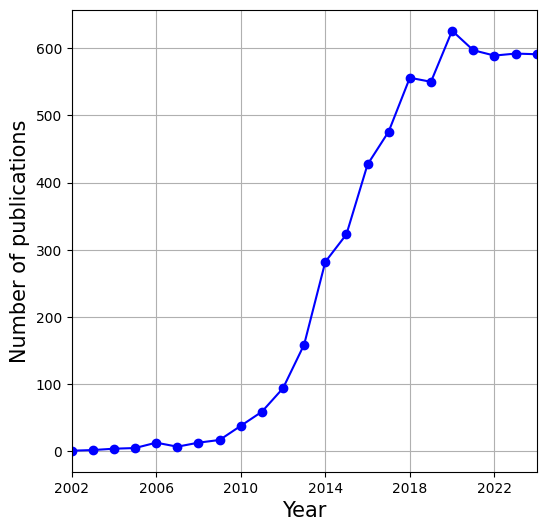

In [30]:
publication_years = data['insert_date'].astype(str).str.extract(r'^(\d{4})').astype(int).values
publication_years = pd.DataFrame(publication_years[publication_years < 2025])
publications_per_year = publication_years.value_counts().sort_index()

plt.figure(figsize=(6, 6))
plt.plot(publications_per_year.index.get_level_values(0), publications_per_year.values, marker='o', linestyle='-', color='b')

plt.xlabel('Year', size=15)
plt.xlim([publication_years.min().values[0], publication_years.max().values[0]])
plt.xticks(range(publication_years.min().values[0], publication_years.max().values[0], 4))
plt.ylabel('Number of publications', size=15)

plt.grid(True)

plt.savefig('../data/output/publications_per_year.pdf')

plt.show()

# Text preprocessing

In [31]:
# Concatenate text columns

df = data[text_cols].copy()
df['text'] = df['title'] + ' ' + df['abstract'] + ' ' + df['index_terms']
df.head()

,title,index_terms,abstract,text
0,2 terminal hybrid hvdc cost effective alternat...,hvdc transmission voltage control circuit faul...,2 terminal hybrid hvdc consisting of a line co...,2 terminal hybrid hvdc cost effective alternat...
1,20 mw level offshore wind power converter base...,switching converters multilevel converters cap...,with the development of offshore wind turbines...,20 mw level offshore wind power converter base...
2,21 level csd based solar multilevel inverter f...,photovoltaic systems induction motor drives he...,as the demand for electricity increases renewa...,21 level csd based solar multilevel inverter f...
3,2n 1 selective harmonic elimination pwm for mo...,switches harmonic analysis pulse width modulat...,the performance of modular multilevel converte...,2n 1 selective harmonic elimination pwm for mo...
4,3 phase high gain pfc converter implementing s...,switches capacitors rectifiers harmonic analys...,in this paper a novel topology of three phase ...,3 phase high gain pfc converter implementing s...


In [32]:
# Eliminate short words
min_word_len = 1
df['text'] = df['text'].str.split(' ').apply(lambda x: [word for word in x if len(word) > min_word_len]).apply(lambda x: ' '.join(x))
df['text']

0       terminal hybrid hvdc cost effective alternativ...
1       20 mw level offshore wind power converter base...
2       21 level csd based solar multilevel inverter f...
3       2n selective harmonic elimination pwm for modu...
4       phase high gain pfc converter implementing swi...
                              ...                        
6283    zero sequence voltage suppression control with...
6284    zero voltage switching double wing multilevel ...
6285    zpuc new configuration of single dc source for...
6286    zpuc mmc real time implementation with model p...
6287    zpuc9 mmc an increased voltage level modular m...
Name: text, Length: 6288, dtype: object

In [33]:
query_text = "Control strategy, closed loop control, nested control, submodules, capacitor voltage, circulating currents, common mode voltage, voltage control, current control, energy control, power control, balancing, model predictive control, proportional integral controller, multi input multi output, modeling, total energy balance, cluster capacitor energy balance, intercluster energy balance, low frequency oscillation mitigation."
query_text = query_text.lower()
query_text = re.sub(r'[^a-z0-9\s]', ' ', query_text) # Remove spacial characters
query_text = word_tokenize(query_text)               # Tokenization
query_text = ' '.join(query_text)                         # Convert back to string
query_text

'control strategy closed loop control nested control submodules capacitor voltage circulating currents common mode voltage voltage control current control energy control power control balancing model predictive control proportional integral controller multi input multi output modeling total energy balance cluster capacitor energy balance intercluster energy balance low frequency oscillation mitigation'

In [34]:
# Apply text preprocessing
words2remove = []
# words2remove = query_text.split(' ')
df['text'] = df['text'].apply(lambda x: preprocess_text(x, words2remove))
df.head()

,title,index_terms,abstract,text
0,2 terminal hybrid hvdc cost effective alternat...,hvdc transmission voltage control circuit faul...,2 terminal hybrid hvdc consisting of a line co...,terminal hybrid hvdc cost effective alternativ...
1,20 mw level offshore wind power converter base...,switching converters multilevel converters cap...,with the development of offshore wind turbines...,mw level offshore wind power converter based s...
2,21 level csd based solar multilevel inverter f...,photovoltaic systems induction motor drives he...,as the demand for electricity increases renewa...,level csd based solar multilevel inverter fed ...
3,2n 1 selective harmonic elimination pwm for mo...,switches harmonic analysis pulse width modulat...,the performance of modular multilevel converte...,n selective harmonic elimination pwm modular m...
4,3 phase high gain pfc converter implementing s...,switches capacitors rectifiers harmonic analys...,in this paper a novel topology of three phase ...,phase high gain pfc converter implementing swi...


# DELETE NON RELATED

Using the indices of the KNN in the full corpus, extract the relevant publications

In [35]:
import json

# Load the array from the JSON file
with open('../data/output/knn_indices.json', 'r') as f:
    knn_indices = json.load(f)

df = df.iloc[knn_indices].copy()
df.reset_index(drop=True, inplace=True)

In [36]:
# Save df
save_data = True
if save_data:
    df.to_csv('../data/input/api/data_cleaned.csv', index=False)

# Word cloud

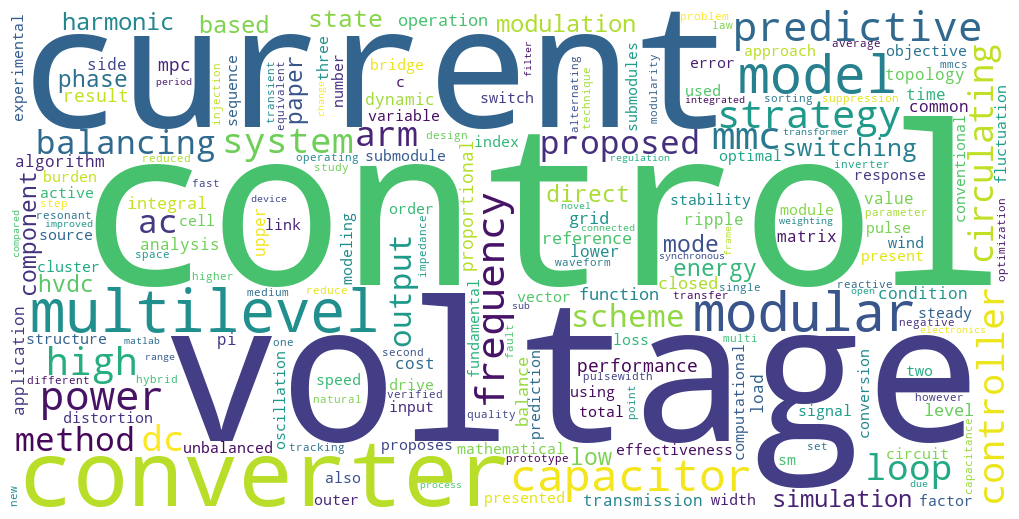

In [37]:
text = ' '.join(df['text'].str.split(' ').explode())
word_cloud(text, save_figure='word_cloud_cluster')

# Vectorization

Tf idf

In [38]:
df_vectorized = df.copy()

In [39]:
vocabulary = ' '.join(df['text']).split(' ')
len(set(vocabulary))*11//10

2931

In [40]:
# Extraer unigramas
vectorizer_unigrams = TfidfVectorizer(ngram_range=(1, 1))
X_unigrams = vectorizer_unigrams.fit_transform(df['text'])
unigram_vocab = set(vectorizer_unigrams.get_feature_names_out())

# # Extraer bigramas, limitando la cantidad
# max_features = len(unigram_vocab) * 1 // 10
# vectorizer_bigrams = TfidfVectorizer(ngram_range=(2, 2), max_features=max_features)
# X_bigrams = vectorizer_bigrams.fit_transform(df['text'])
# bigram_vocab = set(vectorizer_bigrams.get_feature_names_out())

# # Combinar vocabularios
# combined_vocab = list(unigram_vocab) + list(bigram_vocab)

combined_vocab = list(unigram_vocab)

# Vectorizador final usando el vocabulario combinado
vectorizer = TfidfVectorizer(vocabulary=combined_vocab)
X_vectorized = vectorizer.fit_transform(df['text'])
words = vectorizer.get_feature_names_out()

# DataFrame final
df_vectorized = pd.DataFrame(X_vectorized.toarray(), columns=words)

In [41]:
# vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=len(set(vocabulary))*15//10) # No sense to use ngrams, as the frequency of appearance decays rapidly
# X_vectorized = vectorizer.fit_transform(df['text'])
# words = vectorizer.get_feature_names_out()
# df_vectorized = pd.DataFrame(X_vectorized.toarray(), columns=words)

# Save vectorizer
joblib.dump(vectorizer, '../models/vectorizer.pkl')

['../models/vectorizer.pkl']

In [42]:
df_vectorized.columns.str.split(' ').to_series().apply(len).value_counts()

1    2658
Name: count, dtype: int64

In [43]:
df_vectorized.columns

Index(['obtain', 'mbpc', 'ideal', 'consistent', 'become', 'necessary',
       'maintaining', 'save', 'evaluated', 'sfcs',
       ...
       'converge', 'data', 'modulator', 'employee', 'output', 'manage',
       'required', 'affecting', 'healthy', 'foster'],
      dtype='object', length=2658)

In [44]:
len(words), len(vocabulary)

(2658, 63026)

In [45]:
len(set(words)), len(set(vocabulary))

(2658, 2665)

In [46]:
len(set(words) - set(vocabulary))

0

In [47]:
len(set(vocabulary) - set(words))
set(vocabulary) - set(words)

{'c', 'f', 'l', 'n', 'p', 'u', 'x'}

In [48]:
# Vocabulary sorted by Tfidf score
df_vectorized.sum().sort_values()

demonstration     0.058294
slip              0.058294
isolation         0.058294
reaching          0.058294
constructed       0.058294
                   ...    
predictive       25.720294
converter        30.172702
current          39.647215
voltage          52.016758
control          67.260788
Length: 2658, dtype: float64

In [49]:
# Vocabulary sorted by appearance frequency
(df_vectorized != 0).sum().sort_values()

foster          1
solved          1
powerline       1
tv              1
zhangbei        1
             ... 
voltage       300
converter     300
control       300
modular       300
multilevel    300
Length: 2658, dtype: int64

In [50]:
# Save df_vectorized
save_data = True
if save_data:
    df_vectorized.to_csv('../data/output/df_vectorized.csv', index=False)